In [1]:
import sys

print(sys.executable)

C:\Users\ASUS\Desktop\UTS-Graf-Sains-Data\myenv\Scripts\python.exe


In [2]:

import pandas as pd
from pathlib import Path

print("Folder kerja:", Path.cwd())
print("File events.csv ditemukan:", Path("events.csv").exists())

events = pd.read_csv("events.csv")

events["datetime"] = pd.to_datetime(
    events["timestamp"], unit="ms"
)

print("Jumlah baris:", len(events))
print("Tanggal paling awal:", events["datetime"].min())
print("Tanggal paling akhir:", events["datetime"].max())


Folder kerja: C:\Users\ASUS\Desktop\UTS-Graf-Sains-Data
File events.csv ditemukan: True
Jumlah baris: 2756101
Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


In [3]:

# P1: 3 Mei sampai 21 Agustus 2015
# P2: 22 Agustus sampai 18 September 2015

P1 = events[
    (events["datetime"] >= "2015-05-03") &
    (events["datetime"] < "2015-08-22")
].copy()

P2 = events[
    (events["datetime"] >= "2015-08-22") &
    (events["datetime"] < "2015-09-19")
].copy()

total = len(P1) + len(P2)

print("Jumlah data P1:", len(P1))
print("Jumlah data P2:", len(P2))
print("Persentase P1:", round(len(P1) / total * 100, 2), "%")
print("Persentase P2:", round(len(P2) / total * 100, 2), "%")


Jumlah data P1: 2277692
Jumlah data P2: 478409
Persentase P1: 82.64 %
Persentase P2: 17.36 %


In [59]:

P1.to_csv("events_P1_training.csv", index=False)
P2.to_csv("events_P2_testing.csv", index=False)

print("Kedua file periode berhasil disimpan.")


Kedua file periode berhasil disimpan.


In [ ]:
P1 = pd.read_csv("events_P1_training.csv")

print("Ukuran dataset:", P1.shape)
print("\nNama kolom:")
print(P1.columns.tolist())

print("\nJenis interaksi:")
print(P1["event"].value_counts(dropna=False))

print("\nJumlah User unik:", P1["visitorid"].nunique())
print("Jumlah Item unik:", P1["itemid"].nunique())

print("\nData kosong:")
print(P1[["visitorid", "event", "itemid", "timestamp"]].isna().sum())

display(P1.head())

In [5]:

from neo4j import GraphDatabase
import neo4j

print("Driver Neo4j:", neo4j.__version__)
print("Driver berhasil diimpor!")


Driver Neo4j: 6.4.1
Driver berhasil diimpor!


In [6]:

from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "arsalan030406"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

# Tes koneksi
with driver.session(database="neo4j") as session:
    result = session.run("RETURN 'Koneksi berhasil!' AS status")
    print(result.single()["status"])


Koneksi berhasil!


In [57]:
# Memeriksa jumlah node dan relasi di Neo4j
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_node, count(n) AS jumlah
    """)
    print("Jumlah node:")
    for record in result:
        print(record["jenis_node"], ":", record["jumlah"])

    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
    """)
    print("\nJumlah relasi:")
    for record in result:
        print(record["jenis_relasi"], ":", record["jumlah"])

Jumlah node:
['User'] : 1160616
['Item'] : 216156

Jumlah relasi:
INTERACTED : 1827859
SIMILAR_TO : 5



import pandas as pd
from pathlib import Path

# Baca data training
P1 = pd.read_csv("events_P1_training.csv")

print("Ukuran dataset:", P1.shape)
print("\nNama kolom:")
print(P1.columns.tolist())

print("\nJenis interaksi:")
print(P1["event"].value_counts(dropna=False))

print("\nJumlah User unik:", P1["visitorid"].nunique())
print("Jumlah Item unik:", P1["itemid"].nunique())

print("\nData kosong:")
print(P1[["visitorid", "event", "itemid", "timestamp"]].isna().sum())

display(P1.head())


In [10]:

def import_interaction_batch(tx, rows):
    query = """
    UNWIND $rows AS row

    MERGE (u:User {id: row.visitorid})
    MERGE (i:Item {id: row.itemid})

    MERGE (u)-[r:INTERACTED {event: row.event}]->(i)

    SET r.interaction_count = row.interaction_count,
        r.first_timestamp = row.first_timestamp,
        r.last_timestamp = row.last_timestamp

    RETURN count(r) AS processed
    """
    result = tx.run(query, rows=rows)
    return result.single()["processed"]

print("Fungsi impor berhasil disiapkan.")


Fungsi impor berhasil disiapkan.


In [14]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [17]:

from tqdm import tqdm

batch_size = 5000
total = len(interactions)

with driver.session(database="neo4j") as session:
    for start in tqdm(range(0, total, batch_size), desc="Impor ke Neo4j"):
        batch_df = interactions.iloc[start:start + batch_size]
        rows = batch_df.to_dict(orient="records")

        for row in rows:
            row["visitorid"] = int(row["visitorid"])
            row["itemid"] = int(row["itemid"])
            row["interaction_count"] = int(row["interaction_count"])
            row["first_timestamp"] = int(row["first_timestamp"])
            row["last_timestamp"] = int(row["last_timestamp"])

        session.execute_write(import_interaction_batch, rows)

print("Impor graf selesai.")





Impor ke Neo4j:   0%|          | 0/366 [00:00<?, ?it/s]


Impor ke Neo4j:   0%|          | 1/366 [00:02<17:41,  2.91s/it]


Impor ke Neo4j:   1%|          | 2/366 [00:04<11:15,  1.85s/it]


Impor ke Neo4j:   1%|          | 3/366 [00:04<08:39,  1.43s/it]


Impor ke Neo4j:   1%|          | 4/366 [00:05<07:09,  1.19s/it]


Impor ke Neo4j:   1%|▏         | 5/366 [00:06<06:12,  1.03s/it]


Impor ke Neo4j:   2%|▏         | 6/366 [00:07<05:27,  1.10it/s]


Impor ke Neo4j:   2%|▏         | 7/366 [00:07<04:51,  1.23it/s]


Impor ke Neo4j:   2%|▏         | 8/366 [00:08<04:38,  1.29it/s]


Impor ke Neo4j:   2%|▏         | 9/366 [00:09<04:19,  1.37it/s]


Impor ke Neo4j:   3%|▎         | 10/366 [00:09<04:13,  1.41it/s]


Impor ke Neo4j:   3%|▎         | 11/366 [00:10<04:18,  1.37it/s]


Impor ke Neo4j:   3%|▎         | 12/366 [00:11<04:17,  1.37it/s]


Impor ke Neo4j:   4%|▎         | 13/366 [00:11<04:04,  1.45it/s]


Impor ke Neo4j:   4%|▍         | 14/366 [00:12<03:42,  1.58it/s]


Impor ke N

Impor graf selesai.


In [18]:

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (u:User)
        RETURN count(u) AS total
    """).single()
    print("Jumlah User:", result["total"])

    result = session.run("""
        MATCH (i:Item)
        RETURN count(i) AS total
    """).single()
    print("Jumlah Item:", result["total"])

    result = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN count(r) AS total
    """).single()
    print("Jumlah Relasi:", result["total"])


Jumlah User: 1160616
Jumlah Item: 216156
Jumlah Relasi: 1827859


In [19]:

with driver.session(database="neo4j") as session:
    # 1. Menghitung jenis interaksi
    result = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN r.event AS jenis_interaksi,
               count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    print("Jumlah berdasarkan jenis interaksi:")
    for row in result:
        print(row["jenis_interaksi"], ":", row["jumlah"])

    # 2. Lima user dengan relasi terbanyak
    result = session.run("""
        MATCH (u:User)-[r:INTERACTED]->()
        RETURN u.id AS user_id,
               count(r) AS jumlah_interaksi
        ORDER BY jumlah_interaksi DESC
        LIMIT 5
    """)

    print("\n5 User dengan interaksi terbanyak:")
    for row in result:
        print(dict(row))

    # 3. Lima item dengan relasi terbanyak
    result = session.run("""
        MATCH ()-[r:INTERACTED]->(i:Item)
        RETURN i.id AS item_id,
               count(r) AS jumlah_interaksi
        ORDER BY jumlah_interaksi DESC
        LIMIT 5
    """)

    print("\n5 Item dengan interaksi terbanyak:")
    for row in result:
        print(dict(row))


Jumlah berdasarkan jenis interaksi:
view : 1759369
addtocart : 50870
transaction : 17620

5 User dengan interaksi terbanyak:
{'user_id': 1150086, 'jumlah_interaksi': 4343}
{'user_id': 530559, 'jumlah_interaksi': 2329}
{'user_id': 371606, 'jumlah_interaksi': 1597}
{'user_id': 684514, 'jumlah_interaksi': 1584}
{'user_id': 163561, 'jumlah_interaksi': 1513}

5 Item dengan interaksi terbanyak:
{'item_id': 5411, 'jumlah_interaksi': 1931}
{'item_id': 187946, 'jumlah_interaksi': 1777}
{'item_id': 370653, 'jumlah_interaksi': 1405}
{'item_id': 461686, 'jumlah_interaksi': 1305}
{'item_id': 298009, 'jumlah_interaksi': 1198}


In [24]:

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix

# Salin data yang diperlukan untuk VSM
vsm_data = interactions[
    ["visitorid", "itemid", "event", "interaction_count"]
].copy()

# Bobot jenis interaksi
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

vsm_data["weight"] = (
    vsm_data["event"].map(event_weights)
    * vsm_data["interaction_count"]
)

# Membuat indeks User dan Item
user_ids = pd.Index(vsm_data["visitorid"].unique())
item_ids = pd.Index(vsm_data["itemid"].unique())

user_index = user_ids.get_indexer(vsm_data["visitorid"])
item_index = item_ids.get_indexer(vsm_data["itemid"])

# Membuat matriks User-Item dalam format sparse
VSM_User = coo_matrix(
    (
        vsm_data["weight"].to_numpy(dtype=np.float32),
        (user_index, item_index)
    ),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
).tocsr()

# Menggabungkan nilai jika User berinteraksi dengan Item
# melalui beberapa jenis event
VSM_User.sum_duplicates()

print("VSM User berhasil dibuat.")
print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM User:", VSM_User.shape)
print("Jumlah nilai non-zero:", VSM_User.nnz)
print("Kerapatan matriks:", round(
    VSM_User.nnz / (VSM_User.shape[0] * VSM_User.shape[1]) * 100,
    6
), "%")


VSM User berhasil dibuat.
Jumlah User: 1160616
Jumlah Item: 216156
Shape VSM User: (1160616, 216156)
Jumlah nilai non-zero: 1769566
Kerapatan matriks: 0.000705 %


In [22]:

%pip install scipy


Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


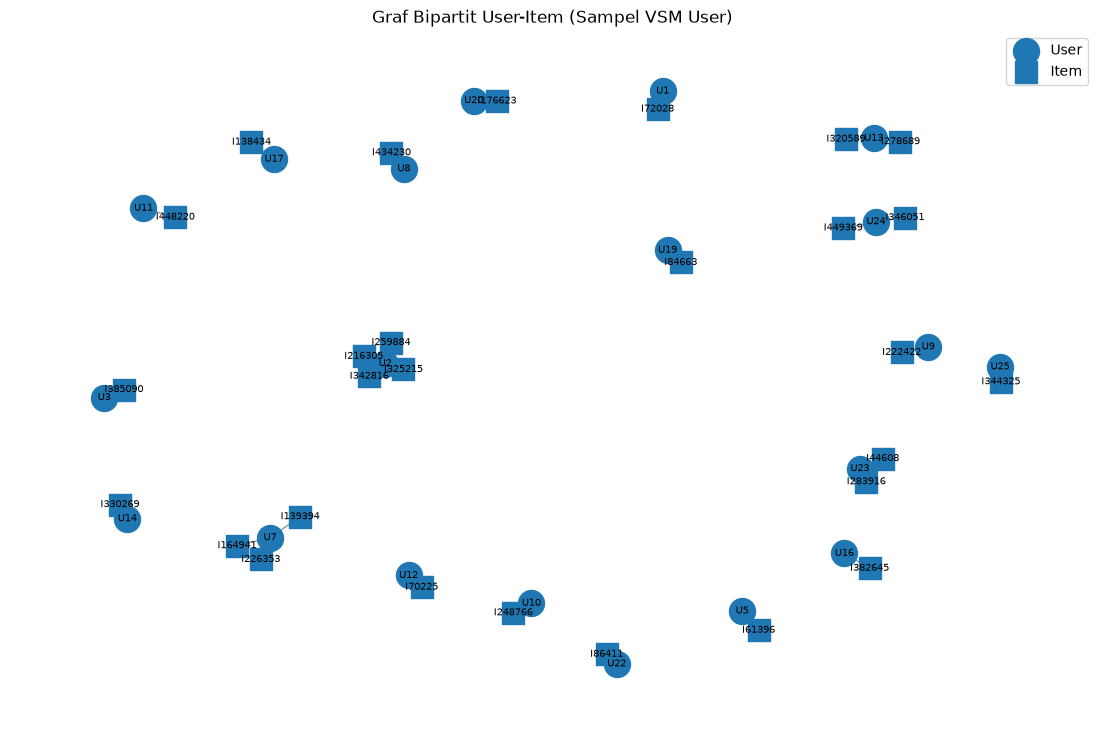

Jumlah node pada graf sampel: 48
Jumlah edge pada graf sampel: 28


In [25]:

import networkx as nx
import matplotlib.pyplot as plt

# Ambil 20 user pertama dan 20 item yang paling banyak muncul
sample_size = 20
sample_user_indices = np.arange(min(sample_size, len(user_ids)))

# Buat graf bipartit dari sampel matriks User-Item
G_user = nx.Graph()

for user_idx in sample_user_indices:
    user_id = int(user_ids[user_idx])
    G_user.add_node(f"U{user_id}", node_type="User")

    row = VSM_User.getrow(user_idx)
    item_indices = row.indices
    item_weights = row.data

    # Batasi maksimal 5 item per user agar plot tidak terlalu padat
    for item_idx, weight in sorted(
        zip(item_indices, item_weights),
        key=lambda x: x[1],
        reverse=True
    )[:5]:
        item_id = int(item_ids[item_idx])
        G_user.add_node(f"I{item_id}", node_type="Item")
        G_user.add_edge(
            f"U{user_id}",
            f"I{item_id}",
            weight=float(weight)
        )

# Plot graf bipartit
plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_user, seed=42)

user_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "User"
]
item_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_user, pos, nodelist=user_nodes,
    node_size=350, node_shape="o", label="User"
)
nx.draw_networkx_nodes(
    G_user, pos, nodelist=item_nodes,
    node_size=250, node_shape="s", label="Item"
)
nx.draw_networkx_edges(G_user, pos, alpha=0.4)
nx.draw_networkx_labels(G_user, pos, font_size=7)

plt.title("Graf Bipartit User-Item (Sampel VSM User)")
plt.legend()
plt.axis("off")
plt.show()

print("Jumlah node pada graf sampel:", G_user.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_user.number_of_edges())


In [26]:

# Membuat VSM Item: baris = Item, kolom = User
VSM_Item = VSM_User.T.tocsr()

print("VSM Item berhasil dibuat.")
print("Jumlah Item:", len(item_ids))
print("Jumlah User:", len(user_ids))
print("Shape VSM Item:", VSM_Item.shape)
print("Jumlah nilai non-zero:", VSM_Item.nnz)
print("Kerapatan matriks:", round(
    VSM_Item.nnz / (VSM_Item.shape[0] * VSM_Item.shape[1]) * 100,
    6
), "%")


VSM Item berhasil dibuat.
Jumlah Item: 216156
Jumlah User: 1160616
Shape VSM Item: (216156, 1160616)
Jumlah nilai non-zero: 1769566
Kerapatan matriks: 0.000705 %


In [27]:

print("Shape VSM User:", VSM_User.shape)
print("Shape VSM Item:", VSM_Item.shape)

print("\nPemeriksaan konsistensi:")
print("VSM Item adalah transpose VSM User:",
      VSM_Item.shape == VSM_User.T.shape)

print("Jumlah non-zero sama:",
      VSM_Item.nnz == VSM_User.nnz)

print("\nPerbandingan ukuran:")
print("Jumlah baris VSM User:", VSM_User.shape[0])
print("Jumlah baris VSM Item:", VSM_Item.shape[0])


Shape VSM User: (1160616, 216156)
Shape VSM Item: (216156, 1160616)

Pemeriksaan konsistensi:
VSM Item adalah transpose VSM User: True
Jumlah non-zero sama: True

Perbandingan ukuran:
Jumlah baris VSM User: 1160616
Jumlah baris VSM Item: 216156


In [29]:

%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [31]:

from sklearn.neighbors import NearestNeighbors
import numpy as np

# Sampel item yang dapat direproduksi
rng = np.random.default_rng(42)
sample_size = min(5000, VSM_Item.shape[0])
sample_indices = np.sort(
    rng.choice(VSM_Item.shape[0], size=sample_size, replace=False)
)

VSM_Item_sample = VSM_Item[sample_indices]

# Cari tetangga terdekat berdasarkan cosine distance
knn_items = NearestNeighbors(
    n_neighbors=2,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
knn_items.fit(VSM_Item_sample)

distances, indices = knn_items.kneighbors(VSM_Item_sample)

# Simpan pasangan unik
similarity_pairs = []
for row_idx in range(len(sample_indices)):
    neighbor_local_idx = indices[row_idx, 1]
    cosine_similarity = 1 - distances[row_idx, 1]

    item_a_idx = sample_indices[row_idx]
    item_b_idx = sample_indices[neighbor_local_idx]

    if item_a_idx < item_b_idx:
        similarity_pairs.append((
            int(item_ids[item_a_idx]),
            int(item_ids[item_b_idx]),
            float(cosine_similarity)
        ))

similarity_df = pd.DataFrame(
    similarity_pairs,
    columns=["item_a", "item_b", "similarity"]
)

similarity_df = (
    similarity_df
    .sort_values("similarity", ascending=False)
    .drop_duplicates(subset=["item_a", "item_b"])
    .head(5)
    .reset_index(drop=True)
)

print("Lima pasangan item paling mirip dalam sampel:")
display(similarity_df)


Lima pasangan item paling mirip dalam sampel:


,item_a,item_b,similarity
0,280299,349378,1.0
1,154264,349378,1.0
2,134049,217326,1.0
3,152802,349378,1.0
4,101888,349378,1.0


In [32]:

# Periksa item-item dari hasil similarity
items_to_check = [280299, 349378, 154264, 134049, 217326, 152802, 101888]

for item_id in items_to_check:
    idx = item_ids.get_loc(item_id)
    vector = VSM_Item.getrow(idx)

    print(
        f"Item {item_id}: "
        f"{vector.nnz} user berinteraksi, "
        f"total bobot = {vector.sum():.0f}"
    )

print("\nPemeriksaan kesamaan vektor:")
for _, row in similarity_df.iterrows():
    idx_a = item_ids.get_loc(int(row["item_a"]))
    idx_b = item_ids.get_loc(int(row["item_b"]))

    vec_a = VSM_Item.getrow(idx_a)
    vec_b = VSM_Item.getrow(idx_b)

    identical = (
        (vec_a != vec_b).nnz == 0
    )

    print(
        f'{int(row["item_a"])} vs {int(row["item_b"])}: '
        f'vektor identik = {identical}'
    )


Item 280299: 1 user berinteraksi, total bobot = 1
Item 349378: 1 user berinteraksi, total bobot = 1
Item 154264: 1 user berinteraksi, total bobot = 1
Item 134049: 1 user berinteraksi, total bobot = 1
Item 217326: 1 user berinteraksi, total bobot = 1
Item 152802: 1 user berinteraksi, total bobot = 1
Item 101888: 1 user berinteraksi, total bobot = 1

Pemeriksaan kesamaan vektor:
280299 vs 349378: vektor identik = True
154264 vs 349378: vektor identik = True
134049 vs 217326: vektor identik = True
152802 vs 349378: vektor identik = True
101888 vs 349378: vektor identik = True


In [33]:

from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

# Hitung jumlah user unik untuk setiap item
user_counts = np.asarray((VSM_Item != 0).sum(axis=1)).ravel()

# Pilih item dengan minimal 5 user unik
eligible_indices = np.where(user_counts >= 5)[0]

print("Total item:", VSM_Item.shape[0])
print("Item dengan minimal 5 user unik:", len(eligible_indices))

# Ambil sampel yang dapat direproduksi
rng = np.random.default_rng(42)
sample_size = min(5000, len(eligible_indices))
sample_indices = np.sort(
    rng.choice(eligible_indices, size=sample_size, replace=False)
)

VSM_Item_sample = VSM_Item[sample_indices]

# Cari tetangga terdekat berdasarkan cosine distance
knn_items = NearestNeighbors(
    n_neighbors=2,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
knn_items.fit(VSM_Item_sample)

distances, indices = knn_items.kneighbors(VSM_Item_sample)

# Ambil pasangan unik
pairs = []
for row_idx in range(len(sample_indices)):
    neighbor_local_idx = indices[row_idx, 1]
    item_a_idx = sample_indices[row_idx]
    item_b_idx = sample_indices[neighbor_local_idx]

    if item_a_idx < item_b_idx:
        pairs.append((
            int(item_ids[item_a_idx]),
            int(item_ids[item_b_idx]),
            float(1 - distances[row_idx, 1])
        ))

similarity_df = pd.DataFrame(
    pairs,
    columns=["item_a", "item_b", "similarity"]
)

similarity_df = (
    similarity_df
    .sort_values("similarity", ascending=False)
    .drop_duplicates(subset=["item_a", "item_b"])
    .head(5)
    .reset_index(drop=True)
)

print("\nLima pasangan item paling mirip setelah penyaringan:")
display(similarity_df)


Total item: 216156
Item dengan minimal 5 user unik: 71312

Lima pasangan item paling mirip setelah penyaringan:


,item_a,item_b,similarity
0,194194,197844,0.921375
1,101393,99427,0.873779
2,55555,238951,0.865603
3,204832,436753,0.858580
4,42841,388333,0.841489


In [34]:

with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.id IS UNIQUE
    """)

print("Constraint Item sudah diperiksa.")


Constraint Item sudah diperiksa.


In [35]:

similarity_records = similarity_df.to_dict(orient="records")

with driver.session(database="neo4j") as session:
    result = session.run("""
        UNWIND $pairs AS pair
        MATCH (a:Item {id: pair.item_a})
        MATCH (b:Item {id: pair.item_b})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.similarity = pair.similarity
        RETURN count(r) AS saved
    """, pairs=similarity_records)

    print("Relasi similarity tersimpan:", result.single()["saved"])


Relasi similarity tersimpan: 5


In [36]:

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN count(r) AS total
    """).single()
    print("Relasi INTERACTED:", result["total"])

    result = session.run("""
        MATCH ()-[r:SIMILAR_TO]->()
        RETURN count(r) AS total
    """).single()
    print("Relasi SIMILAR_TO:", result["total"])


Relasi INTERACTED: 1827859
Relasi SIMILAR_TO: 5


In [38]:

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
        RETURN a.id AS item_a,
               b.id AS item_b,
               r.similarity AS similarity
        ORDER BY similarity DESC
    """)

    for row in result:
        print(dict(row))


{'item_a': 194194, 'item_b': 197844, 'similarity': 0.9213747978210449}
{'item_a': 101393, 'item_b': 99427, 'similarity': 0.8737794756889343}
{'item_a': 55555, 'item_b': 238951, 'similarity': 0.8656028509140015}
{'item_a': 204832, 'item_b': 436753, 'similarity': 0.8585801124572754}
{'item_a': 42841, 'item_b': 388333, 'similarity': 0.8414890170097351}


In [40]:

with driver.session(database="neo4j") as session:
    interacted = session.run("""
        MATCH ()-[r:INTERACTED]->()
        RETURN count(r) AS total
    """).single()["total"]

    similar = session.run("""
        MATCH ()-[r:SIMILAR_TO]->()
        RETURN count(r) AS total
    """).single()["total"]

    print("Relasi INTERACTED:", interacted)
    print("Relasi SIMILAR_TO:", similar)
    print("Total kedua jenis relasi:", interacted + similar)


Relasi INTERACTED: 1827859
Relasi SIMILAR_TO: 5
Total kedua jenis relasi: 1827864


In [41]:
print("P2 tersedia:", "P2" in globals())
print("VSM_User tersedia:", "VSM_User" in globals())
print("VSM_Item tersedia:", "VSM_Item" in globals())
print("interactions tersedia:", "interactions" in globals())

P2 tersedia: True
VSM_User tersedia: True
VSM_Item tersedia: True
interactions tersedia: True


In [42]:

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Data VSM pengguna
X = VSM_User.tocsr()

# Pilih pengguna yang memiliki interaksi pada P1
# sekaligus memiliki interaksi pada P2 untuk evaluasi
p1_users = set(interactions["visitorid"].unique())
p2_users = set(P2["visitorid"].unique())

eligible_users = sorted(p1_users.intersection(p2_users))

# Pilih pengguna secara acak dengan hasil yang reproducible
rng = np.random.default_rng(42)
target_user = int(rng.choice(eligible_users))

# Cari posisi pengguna di dalam matriks VSM
user_position = user_ids.get_loc(target_user)

print("Jumlah pengguna yang memenuhi syarat:", len(eligible_users))
print("ID pengguna terpilih:", target_user)
print("Posisi pengguna di VSM:", user_position)
print("Bentuk matriks VSM:", X.shape)


Jumlah pengguna yang memenuhi syarat: 22730
ID pengguna terpilih: 127499
Posisi pengguna di VSM: 105084
Bentuk matriks VSM: (1160616, 216156)


In [43]:

# Model User-Based KNN dengan k = 5
knn = NearestNeighbors(
    n_neighbors=6,  # 1 pengguna adalah target, 5 lainnya tetangga
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(X)

# Cari tetangga terdekat untuk pengguna target
distances, indices = knn.kneighbors(
    X[user_position],
    n_neighbors=6
)

# Abaikan hasil pertama karena itu pengguna target sendiri
neighbor_positions = indices[0][1:]
neighbor_distances = distances[0][1:]

neighbors_df = pd.DataFrame({
    "visitorid": user_ids[neighbor_positions].to_numpy(),
    "cosine_distance": neighbor_distances,
    "similarity": 1 - neighbor_distances
})

print("5 tetangga terdekat untuk pengguna:", target_user)
display(neighbors_df)


5 tetangga terdekat untuk pengguna: 127499


,visitorid,cosine_distance,similarity
0,1105865,0.0,1.0
1,708611,0.0,1.0
2,677303,0.0,1.0
3,303926,0.0,1.0
4,400200,0.0,1.0


In [44]:

# Periksa profil interaksi pengguna target
target_vector = X[user_position]

print("ID pengguna target:", target_user)
print("Jumlah item dalam profil target:", target_vector.nnz)
print("Total bobot interaksi target:", target_vector.sum())

# Bandingkan profil setiap tetangga dengan target
for neighbor_id in user_ids[neighbor_positions]:
    neighbor_position = user_ids.get_loc(neighbor_id)
    neighbor_vector = X[neighbor_position]

    print(
        f"User {neighbor_id} | "
        f"Jumlah item: {neighbor_vector.nnz} | "
        f"Total bobot: {neighbor_vector.sum():.0f} | "
        f"Vektor identik: {(target_vector != neighbor_vector).nnz == 0}"
    )


ID pengguna target: 127499
Jumlah item dalam profil target: 1
Total bobot interaksi target: 1.0
User 1105865 | Jumlah item: 1 | Total bobot: 1 | Vektor identik: True
User 708611 | Jumlah item: 1 | Total bobot: 1 | Vektor identik: True
User 677303 | Jumlah item: 1 | Total bobot: 1 | Vektor identik: True
User 303926 | Jumlah item: 1 | Total bobot: 1 | Vektor identik: True
User 400200 | Jumlah item: 1 | Total bobot: 2 | Vektor identik: False


In [45]:

# Hitung jumlah item unik yang dimiliki setiap pengguna di P1
items_per_user = interactions.groupby("visitorid")["itemid"].nunique()

# Cari pengguna yang memiliki minimal 5 item di P1
users_with_history = set(
    items_per_user[items_per_user >= 5].index
)

# Pastikan pengguna juga muncul di data pengujian P2
eligible_users_v2 = sorted(
    users_with_history.intersection(set(P2["visitorid"].unique()))
)

# Pilih pengguna secara reproducible
rng = np.random.default_rng(42)
target_user = int(rng.choice(eligible_users_v2))

# Cari posisi pengguna dalam VSM
user_position = user_ids.get_loc(target_user)

print("Jumlah pengguna yang memenuhi syarat:", len(eligible_users_v2))
print("ID pengguna baru:", target_user)
print("Jumlah item unik di P1:", items_per_user.loc[target_user])
print("Jumlah item pada profil VSM:", X[user_position].nnz)


Jumlah pengguna yang memenuhi syarat: 2820
ID pengguna baru: 131894
Jumlah item unik di P1: 5
Jumlah item pada profil VSM: 5


In [46]:

# KNN dengan k = 5
knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(X)

distances, indices = knn.kneighbors(
    X[user_position],
    n_neighbors=6
)

# Buang pengguna target sendiri
neighbor_positions = indices[0][1:]
neighbor_distances = distances[0][1:]

neighbors_df = pd.DataFrame({
    "visitorid": user_ids[neighbor_positions].to_numpy(),
    "cosine_distance": neighbor_distances,
    "similarity": 1 - neighbor_distances
})

print("Pengguna target:", target_user)
print("5 tetangga terdekat:")
display(neighbors_df)


Pengguna target: 131894
5 tetangga terdekat:


,visitorid,cosine_distance,similarity
0,1283255,0.292893,0.707107
1,272666,0.292893,0.707107
2,753503,0.292893,0.707107
3,727261,0.292893,0.707107
4,739411,0.292893,0.707107


In [47]:

# Ambil ID lima tetangga terdekat
neighbor_ids = neighbors_df["visitorid"].to_numpy()
neighbor_similarities = neighbors_df["similarity"].to_numpy()

# Ambil interaksi dari lima tetangga
neighbor_interactions = interactions[
    interactions["visitorid"].isin(neighbor_ids)
].copy()

# Bobot jenis interaksi
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

neighbor_interactions["event_weight"] = (
    neighbor_interactions["event"].map(event_weights)
    * neighbor_interactions["interaction_count"]
)

# Berikan bobot tambahan berdasarkan kemiripan pengguna
similarity_map = dict(zip(neighbor_ids, neighbor_similarities))

neighbor_interactions["recommendation_score"] = (
    neighbor_interactions["event_weight"]
    * neighbor_interactions["visitorid"].map(similarity_map)
)

# Jumlahkan skor setiap item
item_scores = (
    neighbor_interactions.groupby("itemid")["recommendation_score"]
    .sum()
    .sort_values(ascending=False)
)

# Keluarkan item yang sudah pernah diinteraksikan target di P1
seen_items = set(
    interactions.loc[
        interactions["visitorid"] == target_user, "itemid"
    ].unique()
)

recommendations = item_scores[
    ~item_scores.index.isin(seen_items)
].head(3)

recommendations_df = recommendations.reset_index()
recommendations_df.columns = ["itemid", "recommendation_score"]

print("Pengguna target:", target_user)
print("3 rekomendasi item:")
display(recommendations_df)


Pengguna target: 131894
3 rekomendasi item:


,itemid,recommendation_score


In [48]:

print("Jumlah interaksi 5 tetangga:", len(neighbor_interactions))
print("Jumlah item kandidat:", len(item_scores))
print("Jumlah item yang sudah dilihat target:", len(seen_items))
print("Jumlah item yang tersisa:", len(item_scores[~item_scores.index.isin(seen_items)]))

print("\nContoh interaksi tetangga:")
display(
    neighbor_interactions[
        ["visitorid", "itemid", "event", "interaction_count"]
    ].head(10)
)


Jumlah interaksi 5 tetangga: 5
Jumlah item kandidat: 1
Jumlah item yang sudah dilihat target: 5
Jumlah item yang tersisa: 0

Contoh interaksi tetangga:


,visitorid,itemid,event,interaction_count
353505,272666,350895,view,1
945221,727261,350895,view,1
960389,739411,350895,view,1
978383,753503,350895,view,1
1668155,1283255,350895,view,1


In [61]:

# Cari pengguna dengan minimal 5 item unik di P1
items_per_user = interactions.groupby("visitorid")["itemid"].nunique()

candidate_ids = items_per_user[
    (items_per_user >= 5) &
    (items_per_user.index != target_user)
].index

# Batasi kandidat agar perhitungan tetap ringan
rng = np.random.default_rng(42)
candidate_ids = np.array(list(candidate_ids))

if len(candidate_ids) > 20000:
    candidate_ids = rng.choice(
        candidate_ids, size=20000, replace=False
    )

# Posisi kandidat pada matriks VSM
candidate_positions = user_ids.get_indexer(candidate_ids)
valid = candidate_positions >= 0
candidate_ids = candidate_ids[valid]
candidate_positions = candidate_positions[valid]

# Hitung cosine similarity terhadap pengguna target
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(
    X[user_position],
    X[candidate_positions]
).ravel()

# Ambil 5 kandidat paling mirip
top_idx = np.argsort(similarities)[::-1][:5]

neighbors_df = pd.DataFrame({
    "visitorid": candidate_ids[top_idx],
    "similarity": similarities[top_idx]
})

neighbors_df["cosine_distance"] = 1 - neighbors_df["similarity"]

print("Lima tetangga dengan profil lebih beragam:")
display(neighbors_df)


Lima tetangga dengan profil lebih beragam:


,visitorid,similarity,cosine_distance
0,601576,0.336788,0.663212
1,596044,0.312500,0.687500
2,443244,0.226871,0.773129
3,211170,0.187500,0.812500
4,388893,0.166856,0.833144


In [63]:

# Ambil interaksi dari lima tetangga baru
neighbor_ids = neighbors_df["visitorid"].to_numpy()
similarity_map = dict(
    zip(neighbors_df["visitorid"], neighbors_df["similarity"])
)

neighbor_interactions = interactions[
    interactions["visitorid"].isin(neighbor_ids)
].copy()

# Bobot jenis interaksi
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

neighbor_interactions["event_weight"] = (
    neighbor_interactions["event"].map(event_weights)
    * neighbor_interactions["interaction_count"]
)

neighbor_interactions["recommendation_score"] = (
    neighbor_interactions["event_weight"]
    * neighbor_interactions["visitorid"].map(similarity_map)
)

# Skor total per item
item_scores = (
    neighbor_interactions.groupby("itemid")["recommendation_score"]
    .sum()
    .sort_values(ascending=False)
)

# Kecualikan item yang sudah pernah diinteraksikan target di P1
seen_items = set(
    interactions.loc[
        interactions["visitorid"] == target_user, "itemid"
    ].unique()
)

ranked_items = item_scores[
    ~item_scores.index.isin(seen_items)
]

# Simpan top-5 untuk evaluasi
recommendations_top5 = ranked_items.head(5)

# Tampilkan top-3 sesuai kebutuhan tugas
recommendations_df = (
    recommendations_top5.head(3)
    .rename_axis("itemid")
    .reset_index(name="recommendation_score")
)

print("Pengguna target:", target_user)
print("Jumlah kandidat item baru:", len(ranked_items))
print("\nTop-3 rekomendasi:")
display(recommendations_df)

print("\nTop-5 untuk evaluasi:")
display(
    recommendations_top5.rename_axis("itemid")
    .reset_index(name="recommendation_score")
)


Pengguna target: 131894
Jumlah kandidat item baru: 58

Top-3 rekomendasi:


,itemid,recommendation_score
0,402696,2.189970
1,157419,1.334848
2,228392,1.167992



Top-5 untuk evaluasi:


,itemid,recommendation_score
0,402696,2.189970
1,157419,1.334848
2,228392,1.167992
3,52301,0.667424
4,383521,0.625000


In [51]:

# Ambil item yang benar-benar diinteraksikan target pada P2
test_items = set(
    P2.loc[P2["visitorid"] == target_user, "itemid"].unique()
)

# Daftar rekomendasi top-5 dalam urutan peringkat
recommended_items = recommendations_top5.index.tolist()

# Item relevan yang berhasil direkomendasikan
hits = [
    1 if item in test_items else 0
    for item in recommended_items
]

# Hit@5
hit_at_5 = int(sum(hits) > 0)

# DCG@5
dcg_at_5 = sum(
    relevance / np.log2(rank + 2)
    for rank, relevance in enumerate(hits)
)

# IDCG@5: nilai ideal berdasarkan jumlah item relevan
ideal_hits = [1] * min(len(test_items), 5)
idcg_at_5 = sum(
    relevance / np.log2(rank + 2)
    for rank, relevance in enumerate(ideal_hits)
)

# NDCG@5
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("Pengguna target:", target_user)
print("Jumlah item unik pada P2:", len(test_items))
print("Jumlah item relevan di top-5:", sum(hits))
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


Pengguna target: 131894
Jumlah item unik pada P2: 1
Jumlah item relevan di top-5: 0
Hit@5: 0
NDCG@5: 0.0


In [52]:

evaluation_df = pd.DataFrame([{
    "target_user": target_user,
    "k": 5,
    "recommended_items_top3": recommendations_df["itemid"].tolist(),
    "recommended_items_top5": recommendations_top5.index.tolist(),
    "test_items_count": len(test_items),
    "hits_top5": sum(hits),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

display(evaluation_df)


,target_user,k,recommended_items_top3,recommended_items_top5,test_items_count,hits_top5,Hit@5,NDCG@5
0,131894,5,"[402696, 157419, 228392]","[402696, 157419, 228392, 52301, 383521]",1,0,0,0.0


In [66]:

recommended_top3 = recommendations_top5.head(3).index.tolist()
recommended_top5 = recommendations_top5.index.tolist()

evaluation_df = pd.DataFrame([{
    "target_user": target_user,
    "k": 5,
    "recommended_items_top3": str(recommended_top3),
    "recommended_items_top5": str(recommended_top5),
    "test_items_count": len(test_items),
    "hits_top5": int(sum(hits)),
    "Hit@5": int(hit_at_5),
    "NDCG@5": float(ndcg_at_5)
}])

display(evaluation_df.T)


,0
target_user,131894
k,5
recommended_items_top3,"[402696, 157419, 228392]"
recommended_items_top5,"[402696, 157419, 228392, 52301, 383521]"
test_items_count,1
hits_top5,0
Hit@5,0
NDCG@5,0.0


In [67]:
evaluation_df.to_csv("hasil_evaluasi_knn.csv", index=False)
print("Hasil evaluasi berhasil disimpan!")

Hasil evaluasi berhasil disimpan!


In [68]:
import os
print(os.path.abspath("hasil_evaluasi_knn.csv"))

C:\Users\ASUS\Desktop\UTS-Graf-Sains-Data\hasil_evaluasi_knn.csv


Pada tugas ini, saya menggunakan dataset RetailRocket yang berisi aktivitas pengguna saat melihat barang, menambahkan barang ke keranjang, dan melakukan transaksi. Dari data tersebut, saya mencoba melihat hubungan antara pengguna dan barang menggunakan graf di Neo4j.

Selain membuat graf, saya juga menggunakan VSM untuk mengubah data interaksi menjadi matriks, menghitung kemiripan antarbarang, dan membuat rekomendasi barang menggunakan metode KNN. Hasil rekomendasi kemudian diperiksa menggunakan data testing untuk mengetahui apakah barang yang direkomendasikan sesuai dengan aktivitas pengguna berikutnya.

Data dibagi menjadi dua periode, yaitu P1 sebagai data training dan P2 sebagai data testing. Data training digunakan untuk membangun graf dan mencari pola interaksi, sedangkan data testing digunakan untuk mengevaluasi hasil rekomendasi.

Pembagiannya adalah sebagai berikut:

P1: 3 Mei–21 Agustus 2015.
P2: 22 Agustus–18 September 2015.

Dari pembagian tersebut, P1 memiliki 2.277.692 baris dan P2 memiliki 478.409 baris. Data P1 mencakup sekitar 82,64% dari total data kedua periode, sedangkan P2 mencakup 17,36%.

Kedua periode disimpan dalam file CSV yang berbeda agar lebih mudah digunakan pada tahap analisis berikutnya.

Dari data training, terdapat 2.277.692 baris dengan 1.160.616 pengguna dan 216.156 barang. Aktivitas yang paling banyak dilakukan adalah melihat barang (*view*), kemudian menambahkan barang ke keranjang (*addtocart*), dan melakukan transaksi (*transaction*).

Di Neo4j, data ini dibentuk menjadi dua jenis node, yaitu `User` dan `Item`, yang dihubungkan oleh relasi `INTERACTED`. Selain itu, terdapat relasi `SIMILAR_TO` untuk menunjukkan kemiripan antarbarang. Query Cypher digunakan untuk menghitung jumlah node dan relasi serta menampilkan hubungan di dalam graf.

VSM digunakan untuk mengubah aktivitas pengguna menjadi matriks angka. Pada VSM User, baris mewakili pengguna dan kolom mewakili barang, dengan ukuran matriks 1.160.616 × 216.156. Sementara itu, VSM Item merupakan kebalikannya, yaitu 216.156 × 1.160.616.

Bobot interaksi yang digunakan adalah 1 untuk view, 2 untuk addtocart, dan 3 untuk transaction. Matriks ini bersifat sparse, sehingga penyimpanan hanya untuk nilai yang terisi dapat menghemat memori. VSM User cocok untuk melihat kemiripan pengguna, sedangkan VSM Item cocok untuk melihat kemiripan barang.

Visualisasi graf membantu memperlihatkan hubungan antara pengguna dan barang, serta hubungan kemiripan antarbarang yang sudah disimpan di Neo4j.

Kemiripan antarbarang dihitung menggunakan cosine similarity berdasarkan pola interaksi pengguna. Agar prosesnya lebih ringan, perhitungan dilakukan pada sampel maksimal 5.000 barang yang memiliki interaksi dari minimal 5 pengguna, menggunakan random_state=42.

Lima pasangan barang dengan nilai kemiripan tertinggi dari kandidat yang diperoleh adalah:

| Barang A | Barang B | Similarity |
|---:|---:|---:|
| 194194 | 197844 | 0.9214 |
| 101393 | 99427 | 0.8738 |
| 55555 | 238951 | 0.8656 |
| 204832 | 436753 | 0.8586 |
| 42841 | 388333 | 0.8415 |

Hasil tersebut disimpan ke Neo4j menggunakan relasi SIMILAR_TO. Perlu diperhatikan bahwa hasil ini merupakan pasangan terbaik dari kandidat hasil perhitungan pada sampel, bukan peringkat global dari seluruh barang.

Metode KNN digunakan untuk mencari pengguna yang memiliki pola interaksi mirip dengan pengguna target. Pengguna target yang terpilih secara acak dan dapat diulang hasilnya adalah `131894`. Pencarian tetangga dilakukan pada sampel maksimal 20.000 pengguna yang memiliki minimal 5 barang berbeda di data training.

Tiga rekomendasi teratas yang dihasilkan adalah:

| Peringkat | ID Barang | Skor |
|---:|---:|---:|
| 1 | 402696 | 2.189970 |
| 2 | 157419 | 1.334848 |
| 3 | 228392 | 1.167992 |

Evaluasi menggunakan data testing menghasilkan Hit@5 = 0 dan NDCG@5 = 0. Artinya, tidak ada barang dalam lima rekomendasi teratas yang cocok dengan barang yang berinteraksi dengan pengguna target pada periode testing. Hasil ini hanya mewakili satu pengguna, sehingga belum cukup untuk menyimpulkan kualitas rekomendasi secara keseluruhan.

Secara keseluruhan, tugas ini menunjukkan bagaimana data interaksi dapat dibentuk menjadi graf, diolah menggunakan VSM, digunakan untuk menghitung kemiripan barang, dan dimanfaatkan untuk membuat rekomendasi dengan KNN. Hasil evaluasi juga menunjukkan bahwa rekomendasi yang dibuat masih perlu diuji pada lebih banyak pengguna.